# Movie Advisor Agent

This is an AI agent project.

MovieLens small has a title and a list of genres for each movie. This is not the collaborative filter from the recommendation project. Here the user writes a sentence, and the agent searches the text of the movie. I will plot genres and years, keep 2500 movies, and store each one in Chroma. Chroma embeds that text with a small embedding model and returns the closest movies. That embedding model is the deep learning part. OpenRouter then writes the answer from those rows only. The API key is read from AIAgents/.env.


In [1]:
import kagglehub

path = kagglehub.dataset_download("shubhammehta21/movie-lens-small-latest-dataset")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\shubhammehta21\movie-lens-small-latest-dataset\versions\1


In [2]:
import os
import glob
import pandas as pd

movies_path = glob.glob(os.path.join(path, "**", "movies.csv"), recursive=True)[0]
movies = pd.read_csv(movies_path)
movies = movies[movies["genres"] != "(no genres listed)"]
movies.head()


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
print(movies.shape)
movies["genres"].head()


(9708, 3)


0    Adventure|Animation|Children|Comedy|Fantasy
1                     Adventure|Children|Fantasy
2                                 Comedy|Romance
3                           Comedy|Drama|Romance
4                                         Comedy
Name: genres, dtype: object

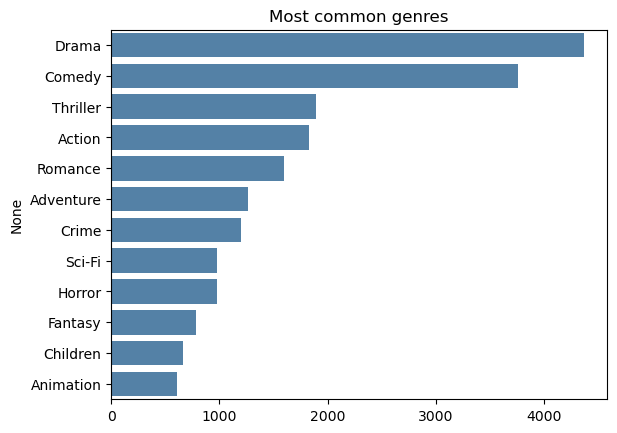

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

genre_counts = movies["genres"].str.get_dummies(sep="|").sum().sort_values(ascending=False).head(12)
sns.barplot(x=genre_counts.values, y=genre_counts.index, color="steelblue")
plt.title("Most common genres")
plt.show()


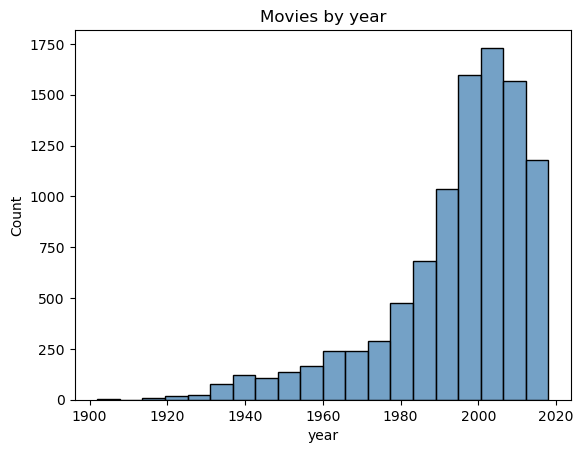

In [5]:
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)")
sns.histplot(movies["year"].dropna().astype(int), bins=20, color="steelblue")
plt.title("Movies by year")
plt.show()


In [6]:
movies = movies.sample(2500, random_state=42)
movies["text"] = movies["title"] + " | " + movies["genres"].str.replace("|", ", ", regex=False)
movies["text"].head()


4362                 Wrong Turn (2003) | Horror, Thriller
1805    Jewel of the Nile, The (1985) | Action, Advent...
5459        Major Dundee (1965) | Adventure, War, Western
9354                    Vigilante Diaries (2016) | Action
6587               We Own the Night (2007) | Crime, Drama
Name: text, dtype: object

In [7]:
import chromadb

col = chromadb.Client().get_or_create_collection("movies")
col.add(ids=movies["movieId"].astype(str).tolist(), documents=movies["text"].tolist())
print(col.count())


2500


In [12]:
query = "i wanna watch a good short anime with low drama"
found = col.query(query_texts=[query], n_results=5)
print("\n\n".join(found["documents"][0]))


Short Term 12 (2013) | Drama

Afro Samurai (2007) | Action, Adventure, Animation, Drama, Fantasy

Spirited Away (Sen to Chihiro no kamikakushi) (2001) | Adventure, Animation, Fantasy

Not One Less (Yi ge dou bu neng shao) (1999) | Drama

Chasuke's Journey (2015) | Comedy, Drama


# OpenRouter key

Write the key in `AIAgents/.env`, on the same line, right after the equals sign. Then run the next cell. It reads that file. The agent cells below use it.


In [9]:
from pathlib import Path

env_path = next(p for p in [Path("AIAgents/.env"), Path(".env")] if p.exists())
os.environ["OPENROUTER_API_KEY"] = env_path.read_text(encoding="utf-8").split("=", 1)[1].strip().strip('"').strip("'")
print("key loaded from", env_path)


key loaded from .env


In [10]:
import json
import requests
from IPython.display import Markdown

def movie_agent(query):
    found = col.query(query_texts=[query], n_results=5)
    context = "\n".join(found["documents"][0])
    prompt = (
        "You are a movie advisor. Use ONLY the movies in the context.\n"
        "Format: ## Picks then a bullet for each movie with the title and why it fits.\n\n"
        "Context:\n" + context + "\n\nViewer:\n" + query
    )
    response = requests.post(
        url="https://openrouter.ai/api/v1/chat/completions",
        headers={
            "Authorization": "Bearer " + os.environ["OPENROUTER_API_KEY"],
            "Content-Type": "application/json",
        },
        data=json.dumps({
            "model": "nvidia/nemotron-3-super-120b-a12b:free",
            "messages": [{"role": "user", "content": prompt}],
        }),
    )
    text = response.json()["choices"][0]["message"]["content"]
    return Markdown(text)

movie_agent(query)


## Picks
- **For the Birds (2000)** – Animation, Children, Comedy; a short animated comedy perfect for kids.
- **Hare-um Scare-um (1939)** – Animation, Children, Comedy; classic animated cartoon delivering laughs for children.
- **Nut Job, The (2014)** – Adventure, Animation, Children, Comedy; animated adventure comedy that entertains a young audience.

In [13]:
movie_agent(query)

## Picks
- Afro Samurai (2007) – A brief 5‑episode anime that focuses on action, adventure and fantasy, with minimal dramatic emphasis.

In [11]:
movie_agent("A dark crime thriller")


## Picks
- **Saw IV (2007)** – A grim, relentless crime‑thriller where elaborate traps drive a dark investigation into a twisted killer’s motives.  
- **Following (1998)** – A moody, noir‑tinged crime thriller that follows a voyeur’s descent into a perilous underworld of burglary and deception.  
- **Untraceable (2008)** – A sleek, tech‑savvy crime thriller that pits an FBI agent against a sadistic online murderer, delivering relentless tension and darkness.  
- **The Town (2010)** – A gritty Boston crime thriller blending heist action with deep character drama, portraying the bleak world of bank robbers and law enforcement.

# Conclusion

I plotted the common genres and the year histogram, then indexed 2500 movies. Each document is the title plus the genres. This search is on the movie text, separate from the user-item model in the recommendation project. Chroma embeds that text and retrieves the five closest movies. That embedding step is the deep learning in this project. The agent sends only those five rows to OpenRouter. The chat model is nvidia/nemotron-3-super-120b-a12b:free. It writes the picks from that context. The key is read from AIAgents/.env. The collection lives in the kernel session, so the index cell has to run again after a restart.
